In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('hotel_bookings.csv')

In [3]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
df.shape

(119390, 32)

In [5]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [7]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [8]:
df.duplicated().sum()

np.int64(31994)

In [9]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [10]:
df['is_canceled'].value_counts()

is_canceled
0    75166
1    44224
Name: count, dtype: int64

In [11]:
df['is_canceled'].value_counts(normalize=True)*100

is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64

In [12]:
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': (df.isnull().sum() / len(df)) * 100
})

missing = missing[missing['Missing Values'] > 0]

missing.sort_values(
    by='Percentage',
    ascending=False
)

,Missing Values,Percentage
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


In [13]:
df.drop('company', axis=1, inplace=True)

In [14]:
df['agent'] = df['agent'].fillna(0)
df['country'] = df['country'].fillna('Unknown')
df['children'] = df['children'].fillna(0)

In [15]:
df.isnull().sum().sort_values(ascending=False).head(10)

hotel                          0
is_repeated_guest              0
reservation_status             0
total_of_special_requests      0
required_car_parking_spaces    0
adr                            0
customer_type                  0
days_in_waiting_list           0
agent                          0
deposit_type                   0
dtype: int64

In [16]:
df.duplicated().sum()

np.int64(32001)

In [17]:
(df.duplicated().sum()/len(df)) * 100

np.float64(26.803752408074377)

In [18]:
df[df.duplicated()].head(10)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,0,No Deposit,240.0,0,Transient,98.00,0,1,Check-Out,2015-07-03
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,1,No Deposit,250.0,0,Transient,84.67,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,0,No Deposit,250.0,0,Transient,137.00,0,1,Check-Out,2015-07-07
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,0,No Deposit,240.0,0,Transient,97.00,0,0,Canceled,2015-07-01
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,0,No Deposit,240.0,0,Transient,109.80,0,3,Check-Out,2015-07-08
219,Resort Hotel,1,1,2015,July,28,8,0,1,2,...,0,No Deposit,0.0,0,Transient,104.72,0,1,Canceled,2015-07-08
256,Resort Hotel,0,91,2015,July,28,10,0,2,2,...,0,No Deposit,240.0,0,Transient,73.80,0,1,Check-Out,2015-07-12
261,Resort Hotel,0,30,2015,July,28,10,2,2,2,...,0,No Deposit,0.0,0,Transient-Party,197.00,0,1,Check-Out,2015-07-14
353,Resort Hotel,0,98,2015,July,29,13,1,1,2,...,0,No Deposit,240.0,0,Transient-Party,82.00,0,3,Check-Out,2015-07-15
372,Resort Hotel,0,40,2015,July,29,13,1,4,2,...,0,No Deposit,250.0,0,Transient,120.00,0,2,Check-Out,2015-07-18


In [19]:
df.drop_duplicates(inplace=True)

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df.shape

(87389, 31)

In [22]:
df = pd.read_csv('hotel_bookings.csv')

In [23]:
df.duplicated().sum()

np.int64(31994)

In [24]:
df.drop_duplicates(inplace=True)

In [25]:
df.drop('company', axis=1, inplace=True)

In [26]:
df['agent'] = df['agent'].fillna(0)
df['country'] = df['country'].fillna('Unknown')
df['children'] = df['children'].fillna(0)

In [27]:
df.shape

(87396, 31)

In [28]:
numeric_cols = df.select_dtypes(include=np.number).columns
(df[numeric_cols] < 0).sum().sort_values(ascending=False)

adr                               1
is_canceled                       0
is_repeated_guest                 0
required_car_parking_spaces       0
days_in_waiting_list              0
agent                             0
booking_changes                   0
previous_bookings_not_canceled    0
previous_cancellations            0
babies                            0
lead_time                         0
children                          0
adults                            0
stays_in_week_nights              0
stays_in_weekend_nights           0
arrival_date_day_of_month         0
arrival_date_week_number          0
arrival_date_year                 0
total_of_special_requests         0
dtype: int64

In [29]:
no_guests = df[
    (df['adults'] == 0) &
    (df['children'] == 0) &
    (df['babies'] == 0)
]
len(no_guests)

166

In [30]:
zero_nights = df[
    (df['stays_in_weekend_nights'] == 0) &
    (df['stays_in_week_nights'] == 0)
]

len(zero_nights)

651

In [31]:
zero_nights = df[
    (df['stays_in_weekend_nights'] == 0) &
    (df['stays_in_week_nights'] == 0)
]
len(zero_nights)

651

In [32]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,87396.0,0.274898,0.446466,0.00,0.0,0.0,1.0,1.0
lead_time,87396.0,79.891368,86.052325,0.00,11.0,49.0,125.0,737.0
arrival_date_year,87396.0,2016.210296,0.686102,2015.00,2016.0,2016.0,2017.0,2017.0
arrival_date_week_number,87396.0,26.838334,13.674572,1.00,16.0,27.0,37.0,53.0
arrival_date_day_of_month,87396.0,15.815541,8.835146,1.00,8.0,16.0,23.0,31.0
stays_in_weekend_nights,87396.0,1.005263,1.031921,0.00,0.0,1.0,2.0,19.0
stays_in_week_nights,87396.0,2.625395,2.053584,0.00,1.0,2.0,4.0,50.0
adults,87396.0,1.875795,0.626500,0.00,2.0,2.0,2.0,55.0
children,87396.0,0.138633,0.455871,0.00,0.0,0.0,0.0,10.0
babies,87396.0,0.010824,0.113597,0.00,0.0,0.0,0.0,10.0


In [33]:
df[df['adr'] < 0]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
14969,Resort Hotel,0,195,2017,March,10,5,4,6,2,...,2,No Deposit,273.0,0,Transient-Party,-6.38,0,0,Check-Out,2017-03-15


In [34]:
no_guests.head(10)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
2224,Resort Hotel,0,1,2015,October,41,6,0,3,0,...,1,No Deposit,0.0,0,Transient-Party,0.0,0,0,Check-Out,2015-10-06
2409,Resort Hotel,0,0,2015,October,42,12,0,0,0,...,0,No Deposit,0.0,0,Transient,0.0,0,0,Check-Out,2015-10-12
3181,Resort Hotel,0,36,2015,November,47,20,1,2,0,...,0,No Deposit,38.0,0,Transient-Party,0.0,0,0,Check-Out,2015-11-23
3684,Resort Hotel,0,165,2015,December,53,30,1,4,0,...,1,No Deposit,308.0,122,Transient-Party,0.0,0,0,Check-Out,2016-01-04
3708,Resort Hotel,0,165,2015,December,53,30,2,4,0,...,1,No Deposit,308.0,122,Transient-Party,0.0,0,0,Check-Out,2016-01-05
4127,Resort Hotel,1,0,2016,February,8,15,0,0,0,...,0,No Deposit,0.0,0,Transient,0.0,0,0,Canceled,2016-02-15
9376,Resort Hotel,1,0,2016,November,48,21,0,0,0,...,0,No Deposit,0.0,0,Group,0.0,0,0,Canceled,2016-11-21
31765,Resort Hotel,0,31,2016,December,53,27,2,8,0,...,3,No Deposit,0.0,0,Transient,28.0,1,0,Check-Out,2017-01-06
32029,Resort Hotel,0,4,2017,January,2,14,0,1,0,...,0,No Deposit,168.0,0,Transient-Party,0.0,0,0,Check-Out,2017-01-15
32827,Resort Hotel,0,46,2017,January,4,25,3,9,0,...,8,No Deposit,0.0,0,Transient,0.0,0,0,Check-Out,2017-02-06


In [35]:
zero_nights.head(10)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,3,No Deposit,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,4,No Deposit,0.0,0,Transient,0.0,0,0,Check-Out,2015-07-01
167,Resort Hotel,0,111,2015,July,28,6,0,0,2,...,0,No Deposit,240.0,0,Transient,0.0,0,2,Check-Out,2015-07-06
168,Resort Hotel,0,0,2015,July,28,6,0,0,1,...,0,No Deposit,250.0,0,Transient,0.0,0,0,Check-Out,2015-07-06
196,Resort Hotel,0,8,2015,July,28,7,0,0,2,...,0,No Deposit,0.0,0,Transient,0.0,0,1,Check-Out,2015-07-07
197,Resort Hotel,0,8,2015,July,28,7,0,0,2,...,0,No Deposit,240.0,0,Transient,0.0,0,1,Check-Out,2015-07-07
459,Resort Hotel,0,6,2015,July,29,17,0,0,2,...,0,No Deposit,240.0,0,Transient,0.0,0,1,Check-Out,2015-07-17
568,Resort Hotel,0,0,2015,July,30,20,0,0,1,...,0,No Deposit,5.0,0,Transient,0.0,0,0,Check-Out,2015-07-20
569,Resort Hotel,0,0,2015,July,30,20,0,0,2,...,0,No Deposit,241.0,0,Transient,0.0,0,1,Check-Out,2015-07-20
618,Resort Hotel,0,16,2015,July,30,23,0,0,2,...,0,No Deposit,242.0,0,Transient,0.0,0,0,Check-Out,2015-07-23


In [36]:
df.nlargest(10, 'adr')[
    ['hotel', 'adr', 'adults', 'children', 'babies',
     'is_canceled', 'total_of_special_requests']
]

,hotel,adr,adults,children,babies,is_canceled,total_of_special_requests
48515,City Hotel,5400.00,2,0.0,0,1,0
111403,City Hotel,510.00,1,0.0,0,0,0
15083,Resort Hotel,508.00,2,0.0,0,0,0
103912,City Hotel,451.50,2,2.0,0,0,4
13142,Resort Hotel,450.00,2,0.0,0,1,0
13391,Resort Hotel,437.00,2,2.0,0,1,0
39155,Resort Hotel,426.25,2,2.0,0,0,2
39568,Resort Hotel,402.00,3,1.0,0,0,1
39118,Resort Hotel,397.38,3,2.0,0,0,1
13323,Resort Hotel,392.00,2,1.0,0,1,0


In [37]:
df.nlargest(10, 'adults')[
    ['hotel', 'adults', 'children', 'babies',
     'adr', 'is_canceled']
]

,hotel,adults,children,babies,adr,is_canceled
2173,Resort Hotel,55,0.0,0,0.0,1
1643,Resort Hotel,50,0.0,0,0.0,1
1539,Resort Hotel,40,0.0,0,0.0,1
1917,Resort Hotel,27,0.0,0,0.0,1
1962,Resort Hotel,27,0.0,0,0.0,1
1587,Resort Hotel,26,0.0,0,0.0,1
1752,Resort Hotel,26,0.0,0,0.0,1
1884,Resort Hotel,26,0.0,0,0.0,1
2003,Resort Hotel,26,0.0,0,0.0,1
2164,Resort Hotel,26,0.0,0,0.0,1


In [38]:
df = df[
    (df['adults'] > 0) |
    (df['children'] > 0) |
    (df['babies'] > 0)
]
df = df[df['adr'] >= 0]

In [39]:
df.shape

(87229, 31)

In [40]:
outlier_cols = [
    'adr',
    'lead_time',
    'stays_in_week_nights',
    'stays_in_weekend_nights',
    'adults',
    'days_in_waiting_list',
    'previous_cancellations'
]

In [41]:
outlier_results = []
for col in outlier_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        'Column': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outliers Count': len(outliers),
        'Outliers Percentage': (len(outliers) / len(df)) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df

,Column,Lower Bound,Upper Bound,Outliers Count,Outliers Percentage
0,adr,-20.525,226.875,2508,2.875191
1,lead_time,-160.000,296.000,2394,2.744500
2,stays_in_week_nights,-3.500,8.500,1514,1.735661
3,stays_in_weekend_nights,-3.000,5.000,213,0.244185
4,adults,2.000,2.000,22733,26.061287
5,days_in_waiting_list,0.000,0.000,855,0.980179
6,previous_cancellations,0.000,0.000,1681,1.927111


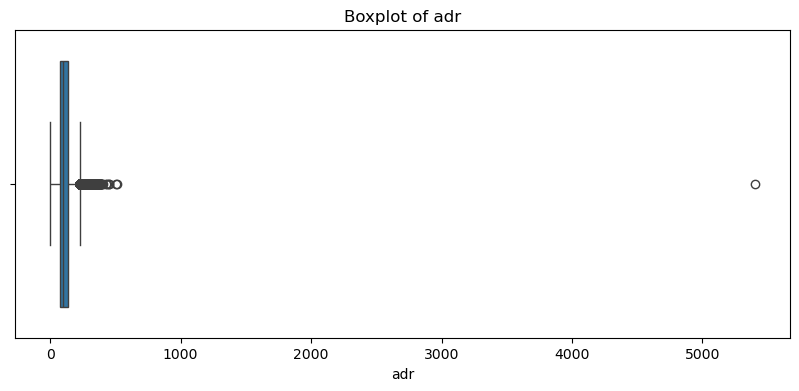

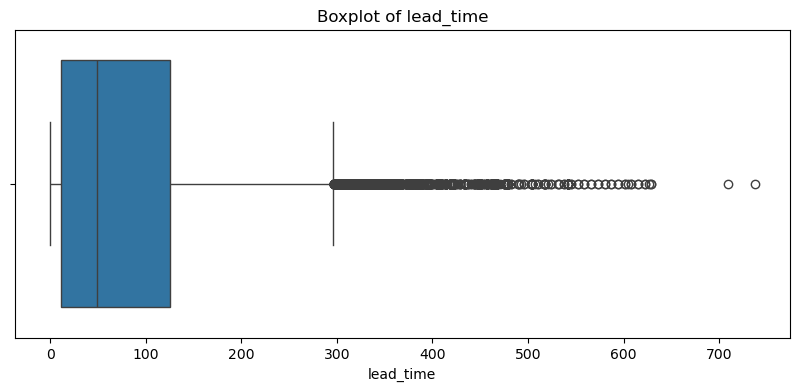

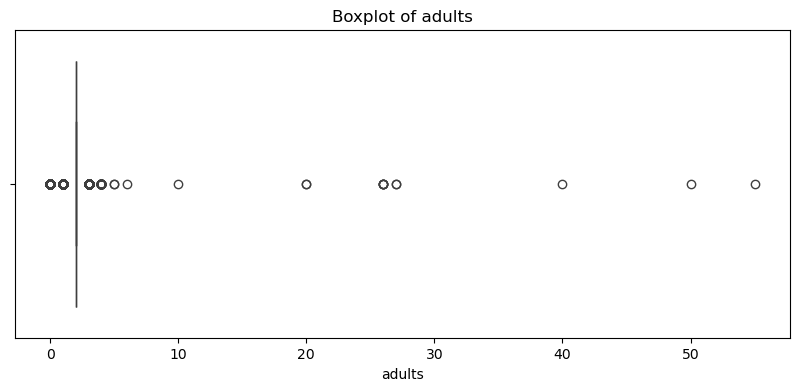

In [42]:
for col in ['adr', 'lead_time', 'adults']:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [43]:
df['is_canceled'].value_counts()

is_canceled
0    63220
1    24009
Name: count, dtype: int64

In [44]:
df['is_canceled'].value_counts(normalize=True) * 100

is_canceled
0    72.475897
1    27.524103
Name: proportion, dtype: float64

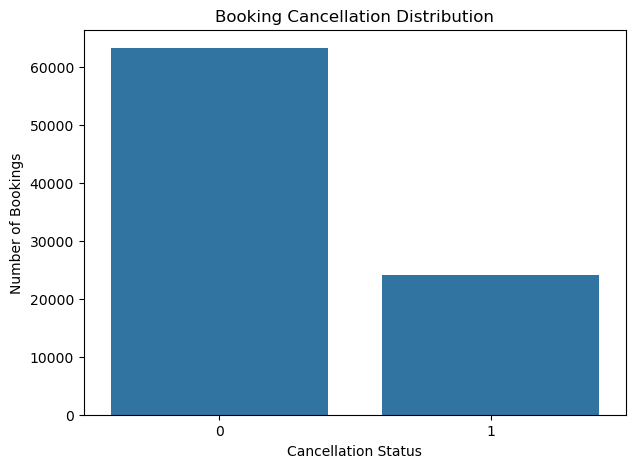

In [45]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='is_canceled')
plt.title('Booking Cancellation Distribution')
plt.xlabel('Cancellation Status')
plt.ylabel('Number of Bookings')
plt.show()

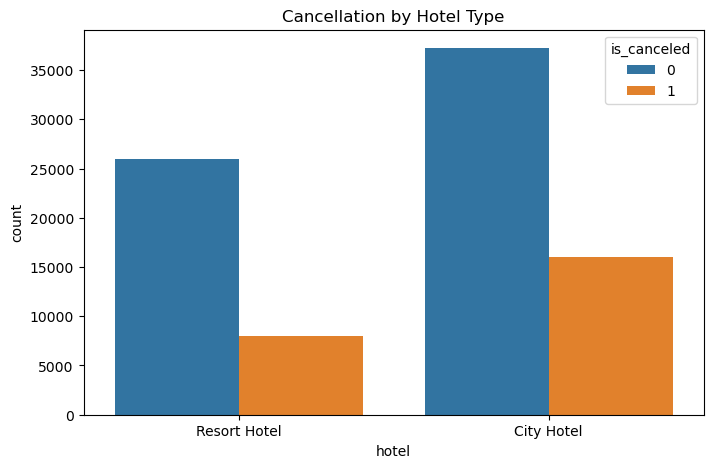

In [46]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='hotel',
    hue='is_canceled'
)

plt.title('Cancellation by Hotel Type')

plt.show()

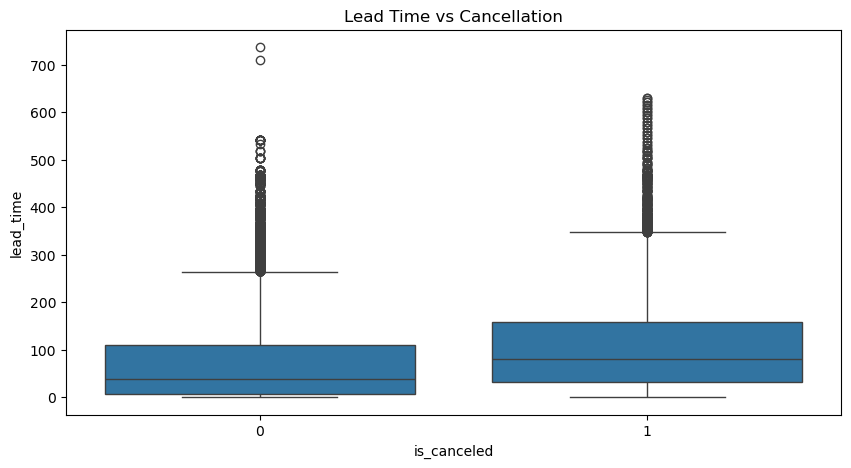

In [47]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='is_canceled',
    y='lead_time'
)

plt.title('Lead Time vs Cancellation')

plt.show()

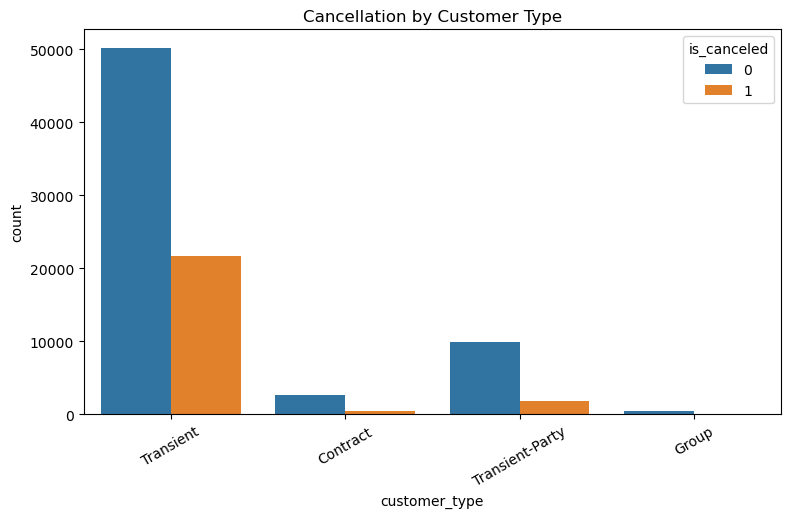

In [48]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='customer_type',
    hue='is_canceled'
)

plt.title('Cancellation by Customer Type')

plt.xticks(rotation=30)

plt.show()

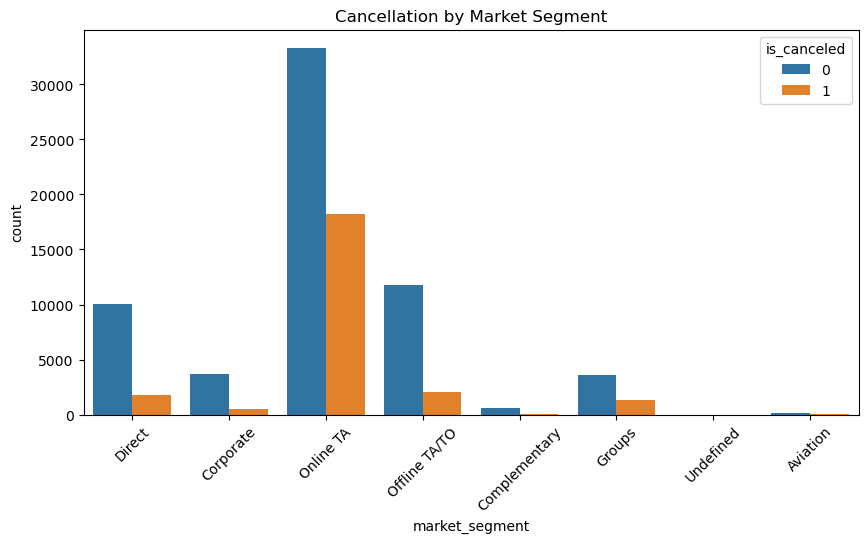

In [49]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='market_segment',
    hue='is_canceled'
)

plt.title('Cancellation by Market Segment')

plt.xticks(rotation=45)

plt.show()

In [50]:
df['total_guests'] = (
    df['adults'] +
    df['children'] +
    df['babies']
)

In [51]:
df['total_nights'] = (
    df['stays_in_week_nights'] +
    df['stays_in_weekend_nights']
)

In [52]:
df['is_family'] = (
    (df['children'] > 0) |
    (df['babies'] > 0)
).astype(int)

In [53]:
df['has_previous_cancellations'] = (
    df['previous_cancellations'] > 0
).astype(int)

In [54]:
season_mapping = {
    'January': 'Winter',
    'February': 'Winter',
    'March': 'Spring',
    'April': 'Spring',
    'May': 'Spring',
    'June': 'Summer',
    'July': 'Summer',
    'August': 'Summer',
    'September': 'Autumn',
    'October': 'Autumn',
    'November': 'Autumn',
    'December': 'Winter'
}

df['arrival_season'] = df['arrival_date_month'].map(season_mapping)

In [55]:
new_features = [
    'total_guests',
    'total_nights',
    'is_family',
    'has_previous_cancellations',
    'arrival_season'
]

df[new_features].head(10)

,total_guests,total_nights,is_family,has_previous_cancellations,arrival_season
0,2.0,0,0,0,Summer
1,2.0,0,0,0,Summer
2,1.0,1,0,0,Summer
3,1.0,1,0,0,Summer
4,2.0,2,0,0,Summer
6,2.0,2,0,0,Summer
7,2.0,2,0,0,Summer
8,2.0,3,0,0,Summer
9,2.0,3,0,0,Summer
10,2.0,4,0,0,Summer


In [56]:
df[new_features].describe(include='all')

,total_guests,total_nights,is_family,has_previous_cancellations,arrival_season
count,87229.000000,87229.000000,87229.000000,87229.000000,87229
unique,NaN,NaN,NaN,NaN,4
top,NaN,NaN,NaN,NaN,Summer
freq,NaN,NaN,NaN,NaN,29041
mean,2.029107,3.628461,0.104357,0.019271,NaN
std,0.790146,2.742879,0.305725,0.137477,NaN
min,1.000000,0.000000,0.000000,0.000000,NaN
25%,2.000000,2.000000,0.000000,0.000000,NaN
50%,2.000000,3.000000,0.000000,0.000000,NaN
75%,2.000000,5.000000,0.000000,0.000000,NaN


In [57]:
df[new_features].isnull().sum()

total_guests                  0
total_nights                  0
is_family                     0
has_previous_cancellations    0
arrival_season                0
dtype: int64

In [58]:
y = df['is_canceled']

In [59]:
drop_cols = [
    'is_canceled',
    'reservation_status',
    'reservation_status_date'
]

In [60]:
X = df.drop(columns=drop_cols)

In [61]:
print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

Features Shape: (87229, 33)
Target Shape: (87229,)


In [62]:
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numeric Features:", numeric_features)

print("Categorical Features:", categorical_features)

Numeric Features: ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_guests', 'total_nights', 'is_family', 'has_previous_cancellations']
Categorical Features: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'arrival_season']


In [63]:
print(X.isnull().sum().sum())

print(y.isnull().sum())

0
0


In [64]:
print("All Features:")
for col in X.columns:
    print(col)

All Features:
hotel
lead_time
arrival_date_year
arrival_date_month
arrival_date_week_number
arrival_date_day_of_month
stays_in_weekend_nights
stays_in_week_nights
adults
children
babies
meal
country
market_segment
distribution_channel
is_repeated_guest
previous_cancellations
previous_bookings_not_canceled
reserved_room_type
assigned_room_type
booking_changes
deposit_type
agent
days_in_waiting_list
customer_type
adr
required_car_parking_spaces
total_of_special_requests
total_guests
total_nights
is_family
has_previous_cancellations
arrival_season


In [65]:
important_cols = ['hotel', 'lead_time', 'arrival_date_year']

for col in important_cols:
    print(col, ":", col in df.columns)

hotel : True
lead_time : True
arrival_date_year : True


In [66]:
print(df.columns.tolist())

['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date', 'total_guests', 'total_nights', 'is_family', 'has_previous_cancellations', 'arrival_season']


In [67]:
y = df['is_canceled']

drop_cols = [
    'is_canceled',
    'reservation_status',
    'reservation_status_date',
    'assigned_room_type',
    'booking_changes',
    'days_in_waiting_list'
]

X = df.drop(columns=drop_cols)

In [68]:
print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("\nImportant Features:")
print('hotel:', 'hotel' in X.columns)
print('lead_time:', 'lead_time' in X.columns)
print('arrival_date_year:', 'arrival_date_year' in X.columns)

print("\nMissing Values:", X.isnull().sum().sum())

X Shape: (87229, 30)
y Shape: (87229,)

Important Features:
hotel: True
lead_time: True
arrival_date_year: True

Missing Values: 0


In [69]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [70]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (69783, 30)
X_test: (17446, 30)
y_train: (69783,)
y_test: (17446,)


In [71]:
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Numeric Features:", len(numeric_features))
print(numeric_features)

print("\nCategorical Features:", len(categorical_features))
print(categorical_features)

Numeric Features: 20
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'agent', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_guests', 'total_nights', 'is_family', 'has_previous_cancellations']

Categorical Features: 10
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type', 'arrival_season']


In [72]:
print("Numeric Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numeric Features:
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'agent', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_guests', 'total_nights', 'is_family', 'has_previous_cancellations']

Categorical Features:
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type', 'arrival_season']


In [73]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [74]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [75]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [76]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

In [77]:
print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['lead_time', 'arrival_date_year',
                                  'arrival_date_week_number',
                                  'arrival_date_day_of_month',
                                  'stays_in_weekend_nights',
                                  'stays_in_week_nights', 'adults', 'children',
                                  'babies', 'is_repeated_guest',
                                  'previous_cancellations',
                                  'previous...
                                  'total_of_special_requests', 'total_guests',
                                  'total_nights', 'is_family',
                                  'has_previous_cancellations']),
                   

In [78]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [79]:
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

In [80]:
logistic_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [81]:
y_pred = logistic_model.predict(X_test)

In [82]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.7974320761206007
Precision: 0.6903903903903904
Recall: 0.4787588504789671
F1 Score: 0.5654205607476636

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.92      0.87     12644
           1       0.69      0.48      0.57      4802

    accuracy                           0.80     17446
   macro avg       0.76      0.70      0.72     17446
weighted avg       0.79      0.80      0.78     17446



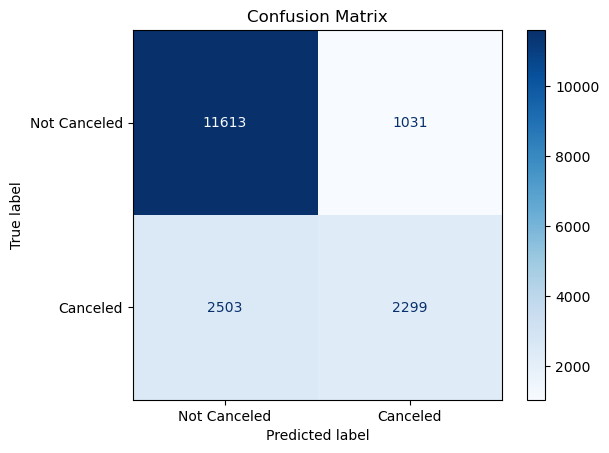

In [83]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Canceled", "Canceled"]
)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [84]:
from sklearn.tree import DecisionTreeClassifier

In [85]:
decision_tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=10,
        class_weight='balanced',
        random_state=42
    ))
])

In [86]:
decision_tree_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [87]:
y_pred_dt = decision_tree_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))

Accuracy: 0.7580534219878482
Precision: 0.5361633262790987
Recall: 0.8969179508538109
F1 Score: 0.6711336190105182


In [88]:
from sklearn.ensemble import RandomForestClassifier

In [89]:
random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [90]:
y_pred_rf = random_forest_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

Accuracy: 0.7703198440903359
Precision: 0.5534202392151593
Recall: 0.8575593502707205
F1 Score: 0.6727109368618802


In [91]:
import pandas as pd

In [92]:
results = pd.DataFrame({
    
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Precision': [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],
    'Recall': [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ]
})

results.sort_values(by='F1 Score', ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.770320,0.553420,0.857559,0.672711
1,Decision Tree,0.758053,0.536163,0.896918,0.671134
0,Logistic Regression,0.797432,0.690390,0.478759,0.565421


In [93]:
rf_classifier = random_forest_model.named_steps['classifier']

feature_names = random_forest_model.named_steps[
    'preprocessor'
].get_feature_names_out()

importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_classifier.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

importance.head(15)

,Feature,Importance
0,num__lead_time,0.120077
170,cat__country_PRT,0.089454
14,num__required_car_parking_spaces,0.087167
218,cat__market_segment_Online TA,0.064984
12,num__agent,0.058384
15,num__total_of_special_requests,0.057745
13,num__adr,0.043146
217,cat__market_segment_Offline TA/TO,0.036680
239,cat__customer_type_Transient,0.028794
223,cat__distribution_channel_TA/TO,0.023592


In [94]:
import joblib

joblib.dump(random_forest_model, 'hotel_cancellation_model.pkl')

['hotel_cancellation_model.pkl']

In [95]:
print("Model saved successfully!")

Model saved successfully!


In [96]:
sample_data = X_test.head(5)

sample_predictions = random_forest_model.predict(sample_data)

print("Predictions:", sample_predictions)

Predictions: [1 1 0 0 0]


In [97]:
comparison = pd.DataFrame({
    'Actual': y_test.head(5).values,
    'Predicted': sample_predictions
})

print(comparison)

   Actual  Predicted
0       0          1
1       1          1
2       0          0
3       0          0
4       0          0


In [98]:
import os

print(os.path.exists('hotel_cancellation_model.pkl'))

True


In [99]:
import joblib

app_data = {
    'numeric_features': numeric_features,
    'categorical_features': categorical_features,
    'X_train': X_train
}

joblib.dump(app_data, 'hotel_app_data.pkl')

print("App data saved successfully!")

App data saved successfully!


In [100]:
app_data = {
    'numeric_features': numeric_features,
    'categorical_features': categorical_features,
    'categories': {
        col: sorted(X_train[col].dropna().unique().tolist())
        for col in categorical_features
    },
    'medians': X_train[numeric_features].median().to_dict(),
    'modes': X_train[categorical_features].mode().iloc[0].to_dict()
}

joblib.dump(app_data, 'hotel_app_data.pkl')

print("App data saved successfully!")

App data saved successfully!


In [101]:
import sklearn
print(sklearn.__version__)

1.7.2
